In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder,
                                   LabelEncoder, TargetEncoder)

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Embedding, Flatten, Dense, Dropout


I0000 00:00:1795458985.900159    3994 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Cargamos el dataset

* Descargamos el csv de nuestro directorio principal del proyecto , mostrando la primera versión de nuestro dataset "dfTaxis"
* Procedemos al tratamiento de los datos y su limpieza
    * Al observar los nulos, mostramos que las únicas columnas con nulos son "SR_FLAG" y "dispatching_base_num" , estas dos no van a ser columnas que sean relevantes frente a nuestro estudio ni en el entrenamiento de nuestro modelo. Por ello , no se intervemdrá en esas dos columnas

In [2]:
dfTaxis=pd.read_csv('sample.csv')
dfTaxis.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag
0,HV0005,B02510,02/12/2019 11:10:30 AM,02/12/2019 11:19:14 AM,80,112,NaN
1,HV0005,B02510,02/12/2019 11:35:27 AM,02/12/2019 11:54:29 AM,256,125,NaN
2,HV0003,B02867,02/12/2019 11:03:14 AM,02/12/2019 11:21:04 AM,210,155,1.0
3,HV0003,B02867,02/12/2019 11:12:12 AM,02/12/2019 11:24:40 AM,155,155,1.0
4,HV0003,B02867,02/12/2019 11:50:05 AM,02/12/2019 11:59:14 AM,155,91,NaN


In [3]:
dfTaxis.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   hvfhs_license_num     200000 non-null  str    
 1   dispatching_base_num  199997 non-null  str    
 2   pickup_datetime       200000 non-null  str    
 3   dropoff_datetime      200000 non-null  str    
 4   PULocationID          200000 non-null  int64  
 5   DOLocationID          200000 non-null  int64  
 6   SR_Flag               43576 non-null   float64
dtypes: float64(1), int64(2), str(4)
memory usage: 10.7 MB


In [4]:
dfTaxis.isnull().sum()

hvfhs_license_num            0
dispatching_base_num         3
pickup_datetime              0
dropoff_datetime             0
PULocationID                 0
DOLocationID                 0
SR_Flag                 156424
dtype: int64

In [5]:
dfTaxis.shape

(200000, 7)

* Para limpiar y preparar los datos creamos de antemano una columna nueva que se llame "duración"
    1. Primero convertirmos los valores de pickup y dropoff a valores datetime
    2. Calculamos la distancia entre estos (duración del viaje) convirtiendo esta en minutos

In [6]:
dfTaxis['pickup_datetime'] = pd.to_datetime(dfTaxis['pickup_datetime'])
dfTaxis['dropoff_datetime'] = pd.to_datetime(dfTaxis['dropoff_datetime'])

dfTaxis['duracion'] = (dfTaxis['dropoff_datetime'] - dfTaxis['pickup_datetime']).dt.total_seconds() / 60

* Al mostrar las estadísticas numéricas de la nueva columna , encontramos que existen viajes con duración de 0 minutos y 0 segundos con fechas de recogida y destino eran iguales
    * Intuímos que estos han sido cancelados y se eliminan de nuestro dataset

In [7]:
dfTaxis['duracion'].describe()

count    200000.000000
mean         18.842232
std          13.039334
min           0.000000
25%           9.600000
50%          15.533333
75%          24.550000
max         371.466667
Name: duracion, dtype: float64

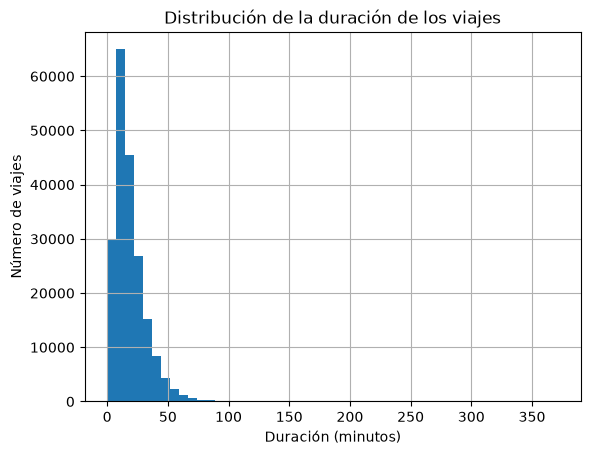

In [8]:
dfTaxis['duracion'].hist(bins=50)
plt.xlabel('Duración (minutos)')
plt.ylabel('Número de viajes')
plt.title('Distribución de la duración de los viajes')
plt.show()

In [9]:
# Viajes con duración igual o inferior a cero
dfTaxis[dfTaxis['duracion'] <= 0]

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
183512,HV0005,B02510,2019-03-21 22:00:40,2019-03-21 22:00:40,217,217,NaN,0.0


In [10]:
taxisClean = dfTaxis[dfTaxis['duracion'] > 0]

## Histogramas y aunar categorías

* Al mostrar los histogramas de nuestras futuras categorías observamso qeu existen varios datos donde se muestran una cantidad de datos menores , es decir , tienen pocos viajes o son zonas poco frecuentes
* Para confirmar esto , mostramos las estadísticas de cuantas veecs aparece una zona , la cual confirma que existen zonas que aparecen solo 1 vez

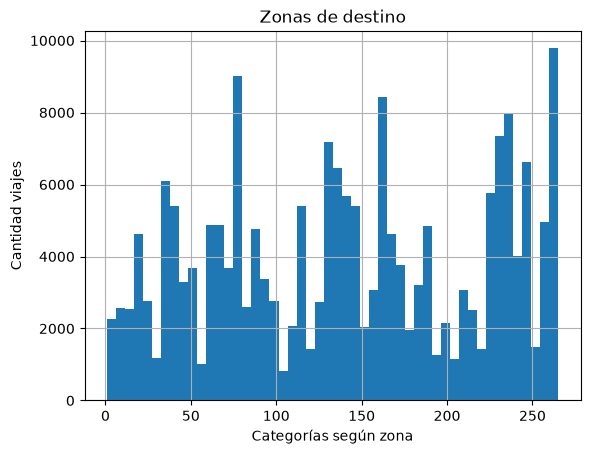

In [11]:
taxisClean['DOLocationID'].hist(bins=50)
#categoruias - localizaciones que tengan pocos viajes = localizaciones poco frecuentes
plt.title('Zonas de destino')
plt.xlabel('Categorías según zona')
plt.ylabel('Cantidad viajes')
plt.show()

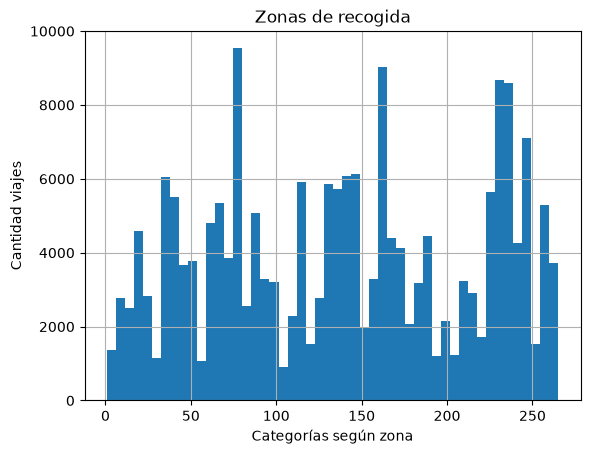

In [12]:
taxisClean['PULocationID'].hist(bins=50)
#categoruias - localizaciones que tengan pocos viajes = localizaciones poco frecuentes
plt.title('Zonas de recogida')
plt.xlabel('Categorías según zona')
plt.ylabel('Cantidad viajes')
plt.show()

In [13]:
taxisClean['PULocationID'].value_counts().describe()

count     260.000000
mean      769.226923
std       698.573499
min         1.000000
25%       214.250000
50%       527.500000
75%      1157.250000
max      3439.000000
Name: count, dtype: float64

In [14]:
taxisClean['DOLocationID'].value_counts().describe()

count     260.000000
mean      769.226923
std       771.788645
min         1.000000
25%       226.750000
50%       522.500000
75%      1136.750000
max      6282.000000
Name: count, dtype: float64

* Para poder decidir el umbral mínimo para aunar nuestras categorías vamos realizando los siguientes pasos :
    * Mostramos el avanze de la cantidad de categorías agrupadas que resultan al aunar las que tengan menos de 70 viajes 
    * Luego de 100 y de 200
* Tenemos que tener en consideración que tenemos 260 categorías en cada una de las columnas-> count  260.000000 , por lo que no podemos elegir un umbral demasiado alto ya que estaríamos agrupando muchas categorías y perdiendo demasiada información.

In [15]:
# Zonas que aparecen menos de 100 veces
print("Recogidas:")
print((taxisClean['PULocationID'].value_counts() < 100).sum())

print("Destinos:")
print((taxisClean['DOLocationID'].value_counts() <100).sum())

Recogidas:
37
Destinos:
34


In [ ]:
countRecogida = taxisClean['PULocationID'].value_counts()
countDestino = taxisClean['DOLocationID'].value_counts()

taxis200Recogida = (taxisClean['PULocationID'].value_counts() < 200).sum()
taxis200Destino = (taxisClean['PULocationID'].value_counts() < 200).sum()

viajesRecogida = countRecogida[countRecogida < 200].sum()
viajesDestino = countDestino[countDestino < 200].sum()

porcentajeEnViajesRecogida = viajesRecogida / len(taxisClean) * 100
porcentajeEnViajesDestino = viajesDestino / len(taxisClean) * 100

print(f"Recogidas: {taxis200Recogida} categorías, {viajesRecogida} viajes ({porcentajeEnViajesRecogida:.2f} %)")
print(f"Destinos: {taxis200Destino} categorías, {viajesDestino} viajes ({porcentajeEnViajesDestino:.2f} %)")

Recogidas: 63 categorías, 5521 viajes (2.76 %)
Destinos: 63 categorías, 5196 viajes (2.60 %)


* Por ello no vamos a elegir un umbral que se acerque mucho al primer cuartil de 25% del número total de categorías , ya que podría provocar que agrupásemos un número elevado de categorías, y que representa una cantidad de viajes considerable pero no demasiado alta .
* Para confirmar esto necesitamos estudiar un umbral que represente un número de categorías considerable y una cantidad de viajes no demasidado alta frente al total ,ya que nos estamso refiriendo a categorías que aparecen poco.


In [17]:
# Obtener la frecuencia de cada zona
frecuencias = taxisClean['PULocationID'].value_counts()

# Identificar las zonas con menos de 100 viajes
zonas_poco_frecuentes = frecuencias[frecuencias < 200].index

# Agruparlas en la categoría 0
taxisClean.loc[taxisClean['PULocationID'].isin(zonas_poco_frecuentes),'PULocationID'] = 0

In [18]:
# Obtener la frecuencia de cada zona
frecuencias = taxisClean['DOLocationID'].value_counts()

# Identificar las zonas con menos de 200 viajes
zonas_poco_frecuentes = frecuencias[frecuencias < 200].index

# Agruparlas en la categoría 0
taxisClean.loc[taxisClean['DOLocationID'].isin(zonas_poco_frecuentes),'DOLocationID'] = 0

In [19]:
print("Categorías de recogida:", taxisClean['PULocationID'].nunique())
print("Categorías de destino:", taxisClean['DOLocationID'].nunique())

print("\nFrecuencia de la categoría genérica:")
print("Recogidas:", (taxisClean['PULocationID'] == 0).sum())
print("Destinos:", (taxisClean['DOLocationID'] == 0).sum())

Categorías de recogida: 198
Categorías de destino: 201

Frecuencia de la categoría genérica:
Recogidas: 5521
Destinos: 5196


## Codificación por embeddings

* Para la codificación por embeddings para dos columnas categóricas realizaemos dos capas de embeddings separadas para poder estudiar la relación del destino con la duración del viaje y de la zona de recogida con la duración del viaje individualmente.
    1. Para trabajar con las categorías en embeddings tendremos que utilizar labelencoder con fittransform
    2. Con estos dos métodos permitimos que primero aprenda las categorías existentes para luego tranformarlas en valores de 0 a 1

* Notas:
    * Si tenemos 260 categorías de recogida, la capa podrá disponer de 260 vectores, uno para cada índice entre 0 y 260
    * Transforma cada categoría en un número entero consecutivo, desde 0 hasta el máximo índice.


In [20]:
LabelEncRecogida=LabelEncoder()
taxisClean['PULocationID']=LabelEncRecogida.fit_transform(taxisClean['PULocationID'])
taxisClean.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
0,HV0005,B02510,2019-02-12 11:10:30,2019-02-12 11:19:14,56,112,NaN,8.733333
1,HV0005,B02510,2019-02-12 11:35:27,2019-02-12 11:54:29,190,125,NaN,19.033333
2,HV0003,B02867,2019-02-12 11:03:14,2019-02-12 11:21:04,151,155,1.0,17.833333
3,HV0003,B02867,2019-02-12 11:12:12,2019-02-12 11:24:40,110,155,1.0,12.466667
4,HV0003,B02867,2019-02-12 11:50:05,2019-02-12 11:59:14,110,91,NaN,9.150000


In [21]:
LabelEncDestino=LabelEncoder()
taxisClean['DOLocationID']=LabelEncDestino.fit_transform(taxisClean['DOLocationID'])
taxisClean.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
0,HV0005,B02510,2019-02-12 11:10:30,2019-02-12 11:19:14,56,78,NaN,8.733333
1,HV0005,B02510,2019-02-12 11:35:27,2019-02-12 11:54:29,190,85,NaN,19.033333
2,HV0003,B02867,2019-02-12 11:03:14,2019-02-12 11:21:04,151,112,1.0,17.833333
3,HV0003,B02867,2019-02-12 11:12:12,2019-02-12 11:24:40,110,112,1.0,12.466667
4,HV0003,B02867,2019-02-12 11:50:05,2019-02-12 11:59:14,110,68,NaN,9.150000


In [22]:
nCategoriasPickup = taxisClean['PULocationID'].nunique()
nCategoriasDropoff = taxisClean['DOLocationID'].nunique()

print("Categorías de recogida:", nCategoriasPickup)
print("Categorías de destino:", nCategoriasDropoff)

Categorías de recogida: 198
Categorías de destino: 201


In [23]:
XPU=taxisClean['PULocationID']
XDO=taxisClean['DOLocationID']
yduracion=taxisClean['duracion'] #target

In [24]:
nCategoriasRecogida=taxisClean[['PULocationID']].value_counts().shape[0]
nCategoriasDestino=taxisClean[['DOLocationID']].value_counts().shape[0]


* Realizamos la capa de embeddings de cada una de las colummas a estudiar
    * Para este paso ajustamos los parámetros en función de nuestro dataset , es decir , calculamos el output con la raiz cuarta y el número de categorías adecuado

In [25]:
#PuLocation
modelRecogida = Sequential()
outputRecogida = int(1.6 * nCategoriasRecogida**0.25)

modelRecogida.add(Embedding(input_dim=nCategoriasRecogida, output_dim=outputRecogida, input_length=1, name="recogida_embedding"))

modelRecogida.add(Flatten())

modelRecogida.add(Dense(32, activation='relu'))
modelRecogida.add(Dropout(0.3))
modelRecogida.add(Dense(1, activation='relu'))

modelRecogida.compile(optimizer='adam',loss='mean_absolute_error', metrics=['mae'])
modelRecogida.summary()
# El modelo intentará predecir el 1 o 0. Para hacerlo, ajustará los pesos del Embedding.

modelRecogida.fit(XPU, yduracion, verbose=1,batch_size=32,
    epochs=4)


/home/carolinamesamartine/proyecto-taxis/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
E0000 00:00:1795459077.552451    3994 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ recogida_embedding (Embedding)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step - loss: 9.4209 - mae: 9.4209
Epoch 2/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 9.0669 - mae: 9.0669
Epoch 3/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 9.0469 - mae: 9.0469
Epoch 4/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 9.0202 - mae: 9.0202


* Vamos a realizar una reduccion de dimensionalidad para representar los embeddings anteriores en 2 dimensiones, partiendo de los embeddings de la red neuronal


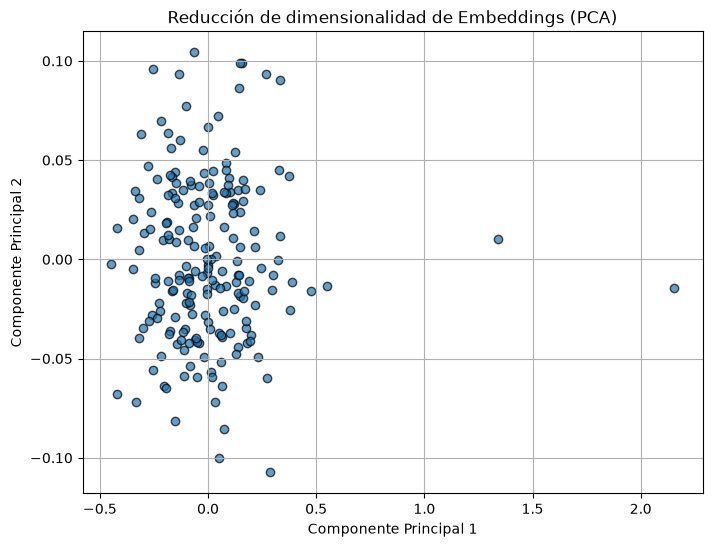

In [26]:

from sklearn.decomposition import PCA

embsRecogida= modelRecogida.get_layer('recogida_embedding').get_weights()[0]

pca_embeddings_recogida = PCA(n_components=2).fit_transform(embsRecogida)


plt.figure(figsize=(8, 6))
plt.scatter(pca_embeddings_recogida[:, 0], pca_embeddings_recogida[:, 1], alpha=0.7, edgecolors='k')

plt.title('Reducción de dimensionalidad de Embeddings (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

## Estudiar categoría de Recogida

* Al mostrar el PCA observamos que tenemos dos puntos muy alejados del centro, asi que procedemos a estudiar una
    * Como los embeddings resultantes están guardados en la variable  'pca_embeddings_recogida' que es un array ,podremos sacar de esa lista estos puntos .
    * Procedemos a filtrar por el valor x de nuestra gráfica , econtrándonos que existen dos puntos como en nuestro gráfico
    * Con el método .classes_ podemos acceder a las categorías originales no codificadas de 0 a 1, esto para poder revisar los datos originales y mirar sus estadísticas
* Procedemos a estudiar la zona 89

In [27]:
indices = np.where(pca_embeddings_recogida[:, 0] > 1.0)[0]
indicesOriginales= LabelEncRecogida.classes_[indices]
indicesOriginales

array([132, 138])

* En su estudio detectamos varias peculiaridades :
    * La media de duración de los viajes en esta categoría es mucho mayor que a la de las demás categorías en general 
    * Ya que en este caso la media de duración son 41.72 minutos y la media en general son 18.84
* Esto se confirma al mostrar una gráfica donde representamos la duración de los viajes , en la zona estudiada se muestra que hay una expansión hacia la derecha , mostrando que los viajes durán mas que la media.

In [28]:
indicesOriginales132=indicesOriginales[0]
datos_zona132 = taxisClean[taxisClean['PULocationID'] == indices[0]]
mediaTiempo=datos_zona132['duracion'].mean()
maxTiempo=datos_zona132['duracion'].max()
print("Zona original:", indicesOriginales132)
print(f"media : {mediaTiempo}, máxima : {maxTiempo}")
datos_zona132['duracion'].describe()

Zona original: 132
media : 41.726085547634476, máxima : 164.85


count    3086.000000
mean       41.726086
std        19.755993
min         0.066667
25%        29.320833
50%        39.983333
75%        52.504167
max       164.850000
Name: duracion, dtype: float64

In [29]:
print("Media general:", taxisClean['duracion'].mean())
print("Media zona 132:", datos_zona132['duracion'].mean())

Media general: 18.842325878296055
Media zona 132: 41.726085547634476


<Axes: >

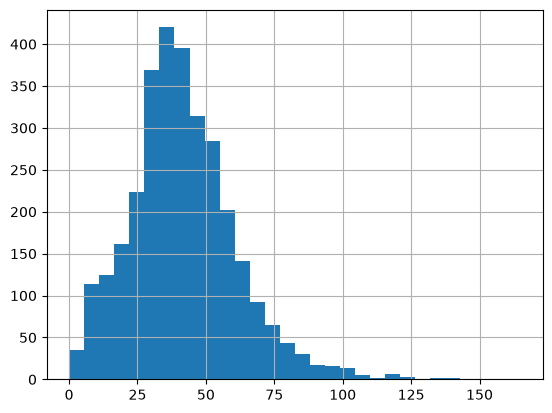

In [30]:
datos_zona132['duracion'].hist(bins=30)

<Axes: >

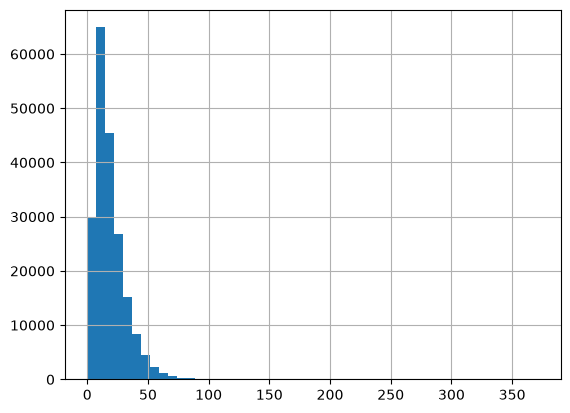

In [31]:
taxisClean['duracion'].hist(bins=50)

In [32]:
#DOLocation
modelDestino = Sequential()
output = int(1.6 * nCategoriasDestino**0.25)

modelDestino.add(Embedding(input_dim=nCategoriasDestino, output_dim=output, input_length=1, name="destino_embedding"))

modelDestino.add(Flatten())

modelDestino.add(Dense(32, activation='relu'))
modelDestino.add(Dropout(0.3))
modelDestino.add(Dense(1, activation='relu'))

modelDestino.compile(optimizer='adam',loss='mean_absolute_error', metrics=['mae'])
modelDestino.summary()
# El modelo intentará predecir el 1 o 0. Para hacerlo, ajustará los pesos del Embedding.

modelDestino.fit(XDO, yduracion, verbose=1,batch_size=32,
    epochs=4)

/home/carolinamesamartine/proyecto-taxis/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ destino_embedding (Embedding)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step - loss: 9.2628 - mae: 9.2628
Epoch 2/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 8.8516 - mae: 8.8516
Epoch 3/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 8.8410 - mae: 8.8410
Epoch 4/4
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - loss: 8.8090 - mae: 8.8090


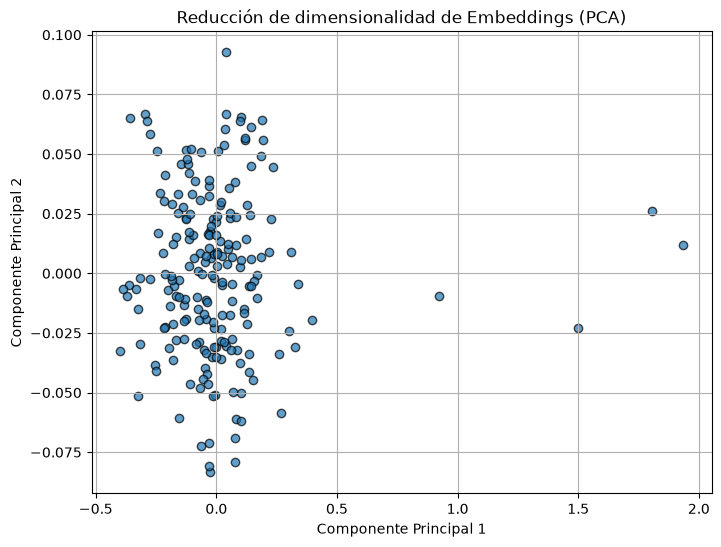

In [33]:
from sklearn.decomposition import PCA

embsdestino= modelDestino.get_layer('destino_embedding').get_weights()[0]

pca_embeddings = PCA(n_components=2).fit_transform(embsdestino)


plt.figure(figsize=(8, 6))
plt.scatter(pca_embeddings[:, 0], pca_embeddings[:, 1], alpha=0.7, edgecolors='k')

plt.title('Reducción de dimensionalidad de Embeddings (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

## Estudiar categoría de destino
* Procedemos a estudiar la categoría 265 que presenta las siguientes anomalías
    * Si las comparamos con varias zonas centrales ,observamos que la zona a estudiar tiene muchos más datos , es decir , muchos más viajes
    * También presenta que tiene una duración superior de sus viajes comparado con las demás zonas 
    * Por ejemplo , si comparamos la zona 265 con dos zonas centrales , encontraremos que estas tienen una media de 14 o 15 , mientras que la zona alejada tiene una media de 36
    * Si hablamos de los máximos y mínimos , econtramos que la zona 1 tiene un viaje con mucha más duración que el máximo de otras zonas centrales
        * zona 1 -> 270 , zonas centrales -> 92 y 80 minutos , lo cual podríamos estar hablando de una zona que está más alejada del inicio general, de las rutas por ubicación

In [74]:
indicesdestino = np.where(pca_embeddings[:, 0] > 1.5)[0]
indicesOriginalesdestino= LabelEncDestino.classes_[indicesdestino]
indicesOriginalesdestino

array([  1, 132, 265])

In [72]:
# indicesdestinoNormales = np.where(pca_embeddings[:, 0] > 0.0)[0]
indicesdestinoNormales = np.where((pca_embeddings[:, 0] < 0.0) &(pca_embeddings[:, 1] > 0.0))[0]
datos_zonaCentral = taxisClean[taxisClean['DOLocationID'] == indicesdestinoNormales[0]]
# datos_zonaCentral
datos_zonaCentral2 = taxisClean[taxisClean['DOLocationID'] == indicesdestinoNormales[1]]
# datos_zonaCentral2

In [73]:
datos_zonaAlejada = taxisClean[taxisClean['DOLocationID'] == indicesdestino[2]]

datos_zonaAlejada['duracion'].describe()

count    6282.000000
mean       36.057336
std        21.728262
min         0.950000
25%        19.887500
50%        32.033333
75%        47.354167
max       270.383333
Name: duracion, dtype: float64

In [75]:
print("DESTINO EXTERIOR 1")
print(datos_zonaAlejada['duracion'].describe())

DESTINO EXTERIOR 1
count    6282.000000
mean       36.057336
std        21.728262
min         0.950000
25%        19.887500
50%        32.033333
75%        47.354167
max       270.383333
Name: duracion, dtype: float64


In [76]:
print("\nDESTINO CENTRAL")
print(datos_zonaCentral['duracion'].describe())

print("\nDESTINO CENTRAL 2")
print(datos_zonaCentral2['duracion'].describe())


DESTINO CENTRAL
count    334.000000
mean      14.727994
std       11.800016
min        0.766667
25%        6.475000
50%       10.958333
75%       19.620833
max       92.433333
Name: duracion, dtype: float64

DESTINO CENTRAL 2
count    380.000000
mean      15.336491
std       10.986162
min        2.333333
25%        7.983333
50%       12.383333
75%       18.670833
max       80.816667
Name: duracion, dtype: float64


In [ ]:
print("Destino central 2:")
print((datos_zonaCentral2['duracion'] > 30).mean() * 100)

print("Destino zona 1:")
print((datos_zonaAlejada['duracion'] > 30).mean() * 100)

print("Destino central 1:")
print((datos_zonaCentral['duracion'] > 30).mean() * 100)


Destino central 2:
11.578947368421053
Destino zona 1:
53.709009869468325
Destino central 1:
11.676646706586826
